In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
df = pd.read_csv("../data/diabetic_data.csv")

In [20]:
df.shape

(101766, 50)


## Dataset Information

- Total records: 101,766
- Total columns: 50
- Each row represents one hospital encounter.
- The dataset contains patient details, hospital visits, diagnoses, medications, and readmission information.

## Column Descriptions

### 1. Patient Information
- encounter_id - Unique ID for each hospital encounter
- patient_nbr - Unique ID for each patient
- race - Race of the patient
- gender - Gender of the patient
- age - Age group of the patient
- weight - Weight range of the patient

### 2. Hospital Admission Information
- admission_type_id - Type of hospital admission
- discharge_disposition_id - Discharge status or destination
- admission_source_id - Source of admission
- time_in_hospital - Number of days spent in hospital
- payer_code - Insurance or payment information
- medical_specialty - Specialty of the treating doctor

### 3. Hospital Visits and Procedures
- num_lab_procedures - Number of lab tests
- num_procedures - Number of other procedures
- num_medications - Number of different medications
- number_outpatient - Outpatient visits in the previous year
- number_emergency - Emergency visits in the previous year
- number_inpatient - Inpatient visits in the previous year

### 4. Diagnosis Information
- diag_1 - Primary diagnosis
- diag_2 - Secondary diagnosis
- diag_3 - Third diagnosis
- number_diagnoses - Total number of diagnoses

### 5. Blood Test Results
- max_glu_serum - Glucose serum test result
- A1Cresult - HbA1c test result

### 6. Diabetes Medications
These columns show the status of different diabetes medications.

- metformin - Metformin
- repaglinide - Repaglinide
- nateglinide - Nateglinide
- chlorpropamide - Chlorpropamide
- glimepiride - Glimepiride
- acetohexamide - Acetohexamide
- glipizide - Glipizide
- glyburide - Glyburide
- tolbutamide - Tolbutamide
- pioglitazone - Pioglitazone
- rosiglitazone - Rosiglitazone
- acarbose - Acarbose
- miglitol - Miglitol
- troglitazone - Troglitazone
- tolazamide - Tolazamide
- examide - Examide
- citoglipton - Citoglipton
- insulin - Insulin
- glyburide-metformin - Combination medication
- glipizide-metformin - Combination medication
- glimepiride-pioglitazone - Combination medication
- metformin-rosiglitazone - Combination medication
- metformin-pioglitazone - Combination medication

Medication values:
- No - Medication not prescribed
- Steady - No change in dosage
- Up - Dosage increased
- Down - Dosage decreased

### 7. Other Medication Information
- change - Whether diabetes medication was changed
- diabetesMed - Whether diabetes medication was prescribed

### 8. Target Column
- readmitted - Shows whether the patient was readmitted

Original values:
- `<30` - Readmitted within 30 days
- `>30` - Readmitted after 30 days
- `NO` - No recorded readmission



In [21]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### 13 numerical columns, and 37 object columns

## checking missing values

In [23]:
missing_values = df.isnull().sum()
percentage = (missing_values/len(df))*100

missing_data = pd.DataFrame({'missing':missing_values, 'Percentage': percentage})
missing_data[missing_data ['missing']>0 ]

,missing,Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


In [24]:
for col in df.columns:
    count = (df[col] =='?').sum()
    
    if count>0:
        print(col, count)

race 2273
weight 98569
payer_code 40256
medical_specialty 49949
diag_1 21
diag_2 358
diag_3 1423


In [25]:
df['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

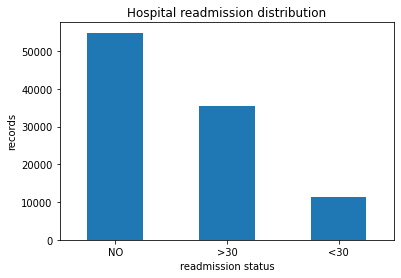

In [26]:
#visualization of the target variable
readmission_count = df['readmitted'].value_counts()
readmission_count.plot(kind='bar')
plt.title('Hospital readmission distribution')
plt.xlabel('readmission status')
plt.ylabel('records')
plt.xticks(rotation=0)
plt.show()

### We can see our dataset is imbalanced and most record belong to the group that was not readmitted within 30 days

In [27]:
df['age'].value_counts()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

## checking readmission rate by age

In [28]:
''' checking readmission rate by age. making a new column for 30day readmission and finding the 
readmission percentage for each age group
'''

df['readmitted_30'] = (df['readmitted'] == '<30').astype(int)
age_readmission = df.groupby('age')['readmitted_30'].mean() * 100

print(age_readmission)

age
[0-10)       1.863354
[10-20)      5.788712
[20-30)     14.242607
[30-40)     11.231788
[40-50)     10.604027
[50-60)      9.666203
[60-70)     11.128408
[70-80)     11.773055
[80-90)     12.083503
[90-100)    11.099177
Name: readmitted_30, dtype: float64


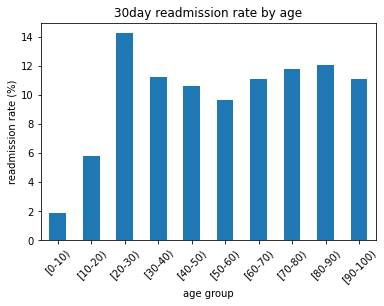

In [29]:
age_readmission.plot(kind='bar')
plt.title('30day readmission rate by age')
plt.xlabel('age group')
plt.ylabel('readmission rate (%)')
plt.xticks(rotation=45)
plt.show()

## exploring time spent in the hospital

In [30]:
df['time_in_hospital'].describe()

count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64

In [31]:
#comparing hospital stay with readmission

stay_readmission=df.groupby('time_in_hospital')['readmitted_30'].mean()
stay_readmission = stay_readmission*100 #we are converting to percent
stay_readmission

time_in_hospital
1      8.178491
2      9.939619
3     10.666817
4     11.806952
5     12.030905
6     12.587876
7     12.834955
8     14.233660
9     13.724184
10    14.346712
11    10.512129
12    13.328729
13    12.314050
14    12.955854
Name: readmitted_30, dtype: float64

In [32]:
''' looks like readmission rates generally increase with longer hospital stays but the relationship 
is not perfectly consistent'''

' looks like readmission rates generally increase with longer hospital stays but the relationship \nis not perfectly consistent'

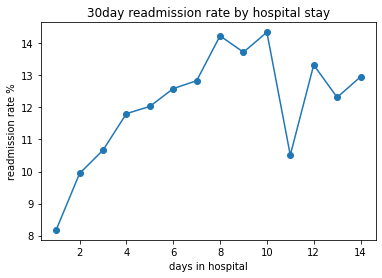

In [33]:
stay_readmission.plot(kind='line',marker='o')
plt.title('30day readmission rate by hospital stay')
plt.xlabel('days in hospital')
plt.ylabel('readmission rate %')
plt.show()

In [34]:
## exploring previous hospital visits

In [36]:
df[['number_inpatient','number_emergency', 'number_outpatient']].describe()

,number_inpatient,number_emergency,number_outpatient
count,101766.000000,101766.000000,101766.000000
mean,0.635566,0.197836,0.369357
std,1.262863,0.930472,1.267265
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000
max,21.000000,76.000000,42.000000


In [38]:
''' All three columns have a median of 0. This means at least half of the encounters have no recorded previous visits in each category.
The average number of previous inpatient visits is 0.64, compared with 0.20 emergency visits and 0.37 outpatient visits.
Patients with frequent hospital visits may have more complicated medical conditions.
'''

' All three columns have a median of 0. This means at least half of the encounters have no recorded previous visits in each category.\nThe average number of previous inpatient visits is 0.64, compared with 0.20 emergency visits and 0.37 outpatient visits.\nPatients with frequent hospital visits may have more complicated medical conditions.\n'

In [39]:
## checking readmission rate by previous inpatient visits

In [40]:
inpatient_readmission = df.groupby('number_inpatient')['readmitted_30'].mean()
inpatient_readmission = inpatient_readmission*100 #converting to percent
inpatient_readmission

number_inpatient
0       8.437084
1      12.924543
2      17.433254
3      20.287306
4      23.612824
5      31.403941
6      34.583333
7      35.447761
8      44.370861
9      42.342342
10     42.622951
11     67.346939
12     50.000000
13     50.000000
14     40.000000
15    100.000000
16     33.333333
17    100.000000
18      0.000000
19     50.000000
21    100.000000
Name: readmitted_30, dtype: float64

In [41]:
'''The readmission rate generally increases with the number of previous inpatient visits. It rises from 8.44% for no previous visits to 31.40% for five visits. This suggests that previous inpatient visits could be useful for predicting readmission. However, some higher visit counts show unusual percentages, possibly because they have very few records.'''

'The readmission rate generally increases with the number of previous inpatient visits. It rises from 8.44% for no previous visits to 31.40% for five visits. This suggests that previous inpatient visits could be useful for predicting readmission. However, some higher visit counts show unusual percentages, possibly because they have very few records.'

In [42]:
#checking the number of encounters
inpatient_count = df['number_inpatient'].value_counts()
inpatient_count = inpatient_count.sort_index()
print(inpatient_count)

number_inpatient
0     67630
1     19521
2      7566
3      3411
4      1622
5       812
6       480
7       268
8       151
9       111
10       61
11       49
12       34
13       20
14       10
15        9
16        6
17        1
18        1
19        2
21        1
Name: count, dtype: int64


In [43]:
'''Most encounters had no previous inpatient visits (67,630). As the number of previous visits increases, the number of encounters decreases. For example, only 9 encounters had 15 previous visits, and just 1 had 17 visits. This explains why some groups showed 100% readmission rates. Those percentages are based on very few records and may not be reliable.'''

'Most encounters had no previous inpatient visits (67,630). As the number of previous visits increases, the number of encounters decreases. For example, only 9 encounters had 15 previous visits, and just 1 had 17 visits. This explains why some groups showed 100% readmission rates. Those percentages are based on very few records and may not be reliable.'

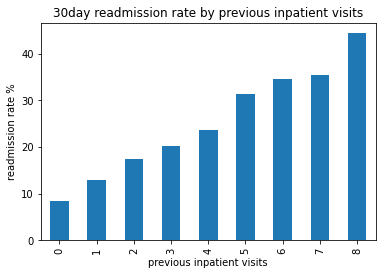

In [47]:
inpatient_graph = inpatient_readmission.loc[0:8]
inpatient_graph.plot(kind='bar')
plt.title('30day readmission rate by previous inpatient visits')
plt.xlabel('previous inpatient visits')
plt.ylabel('readmission rate %')
plt.show()

In [48]:
'''The readmission rate increases as the number of previous inpatient visits increases. It rises from 8.44% for patients with no previous inpatient visits to 44.37% for those with eight visits. This suggests that previous inpatient visits could be an important feature for predicting hospital readmission.'''

'The readmission rate increases as the number of previous inpatient visits increases. It rises from 8.44% for patients with no previous inpatient visits to 44.37% for those with eight visits. This suggests that previous inpatient visits could be an important feature for predicting hospital readmission.'

In [49]:
#exploring previous emergency visits
emergency_readmission = df.groupby('number_emergency')['readmitted_30'].mean()
emergency_readmission = emergency_readmission*100
print(emergency_readmission)

number_emergency
0      10.474315
1      14.354566
2      18.266405
3      20.275862
4      30.748663
5      24.479167
6      23.404255
7      26.027397
8      32.000000
9      36.363636
10     35.294118
11     21.739130
12     20.000000
13     33.333333
14      0.000000
15     33.333333
16     40.000000
18     20.000000
19     50.000000
20     50.000000
21     50.000000
22     50.000000
24      0.000000
25      0.000000
28    100.000000
29      0.000000
37      0.000000
42      0.000000
46      0.000000
54      0.000000
63      0.000000
64    100.000000
76      0.000000
Name: readmitted_30, dtype: float64


In [50]:
'''The readmission rate generally increases with previous emergency visits. It rises from 10.47% for no emergency visits to 30.75% for four visits. However, the rates fluctuate for higher visit counts, possibly because there are fewer records in those groups.'''

'The readmission rate generally increases with previous emergency visits. It rises from 10.47% for no emergency visits to 30.75% for four visits. However, the rates fluctuate for higher visit counts, possibly because there are fewer records in those groups.'

In [51]:
emergency_count = df['number_emergency'].value_counts()
emergency_count = emergency_count.sort_index()
emergency_count

number_emergency
0     90383
1      7677
2      2042
3       725
4       374
5       192
6        94
7        73
8        50
9        33
10       34
11       23
12       10
13       12
14        3
15        3
16        5
18        5
19        4
20        4
21        2
22        6
24        1
25        2
28        1
29        1
37        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

In [52]:
'''Most encounters had no previous emergency visits. The number of encounters decreases as emergency visits increase. Some higher visit counts have very few records, so their readmission percentages may not be reliable.'''

'Most encounters had no previous emergency visits. The number of encounters decreases as emergency visits increase. Some higher visit counts have very few records, so their readmission percentages may not be reliable.'

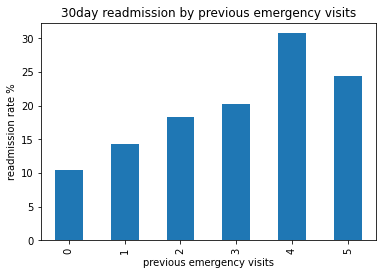

In [53]:
emergency_graph = emergency_readmission.loc[0:5]
emergency_graph.plot(kind='bar')
plt.title('30day readmission by previous emergency visits')
plt.xlabel('previous emergency visits')
plt.ylabel('readmission rate %')
plt.show()

In [54]:
#exploring previous outpatient visits

outpatient_readmission = df.groupby('number_outpatient')['readmitted_30'].mean()

outpatient_readmission =outpatient_readmission* 100
outpatient_readmission


number_outpatient
0      10.674256
1      13.923014
2      13.745131
3      12.291871
4      15.104641
5      11.819887
6      13.201320
7      15.483871
8       5.102041
9      15.662651
10      8.771930
11     14.285714
12     20.000000
13     19.354839
14     17.857143
15     10.000000
16      0.000000
17     12.500000
18      0.000000
19     33.333333
20      0.000000
21      0.000000
22     20.000000
23     50.000000
24      0.000000
25      0.000000
26      0.000000
27      0.000000
28      0.000000
29      0.000000
33      0.000000
34      0.000000
35      0.000000
36      0.000000
37      0.000000
38      0.000000
39      0.000000
40    100.000000
42      0.000000
Name: readmitted_30, dtype: float64

In [55]:
'''The readmission rate changes across different numbers of outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a different relationship with readmission compared to inpatient and emergency visits.'''

'The readmission rate changes across different numbers of outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a different relationship with readmission compared to inpatient and emergency visits.'

In [56]:
outpatient_count = df['number_outpatient'].value_counts()
outpatient_count = outpatient_count.sort_index()

outpatient_count


number_outpatient
0     85027
1      8547
2      3594
3      2042
4      1099
5       533
6       303
7       155
8        98
9        83
10       57
11       42
12       30
13       31
14       28
15       20
16       15
17        8
18        5
19        3
20        7
21        7
22        5
23        2
24        3
25        2
26        2
27        3
28        1
29        2
33        2
34        1
35        2
36        2
37        1
38        1
39        1
40        1
42        1
Name: count, dtype: int64

In [57]:
'''Most encounters had no previous outpatient visits. The number of encounters decreases as previous outpatient visits increase. Some higher visit counts have very few records, which may explain the unusual readmission percentages.'''

'Most encounters had no previous outpatient visits. The number of encounters decreases as previous outpatient visits increase. Some higher visit counts have very few records, which may explain the unusual readmission percentages.'

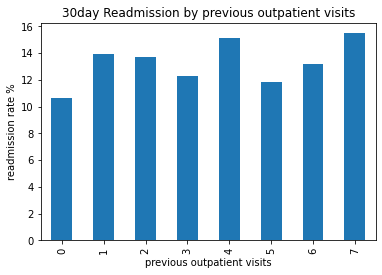

In [58]:
outpatient_graph = outpatient_readmission.loc[0:7]
outpatient_graph.plot(kind='bar' )

plt.title('30day Readmission by previous outpatient visits')
plt.xlabel('previous outpatient visits')
plt.ylabel('readmission rate %')
plt.show()


In [59]:
'''The readmission rate varies with the number of previous outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a weaker relationship with 30-day readmission than inpatient visits.'''

'The readmission rate varies with the number of previous outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a weaker relationship with 30-day readmission than inpatient visits.'